In [167]:
import pandas as pd
import numpy as np

# 1. Загрузка и первичный осмотр данных

In [168]:
data = pd.read_csv('autokz2019.csv', encoding='utf-8', sep=';', decimal=',')
data.drop(columns=[
    'Сегмент',
    'Тип клиента',
    'Модификация',
    'Наименование дилерского центра',
    'Форма расчета',
    'Сегментация Eng',
    'Локализация производства',
], inplace=True)
data.rename(columns={  
    'Год': 'year',
    'Месяц': 'month',
    'Компания': 'company',
    'Бренд': 'brand',
    'Модель': 'model',
    'Год выпуска': 'year_of_release',
    'Страна-производитель': 'country_of_production',
    'Вид топлива': 'fuel_type',
    'Объём двиг, л': 'engine_volume',
    'Коробка передач': 'transmission',
    'Тип привода': 'drive_type',
    'Регион': 'region',
    'Количество': 'quantity',
    'Цена, USD': 'price_usd',
    'Продажа, USD': 'sale_usd',
    'Область': 'area',
    'Сегментация 2013': 'segmentation_2013',
    'Класс 2013': 'class_2013',
    'Объём двиг, л,': 'engine_volume',
}, inplace=True)

In [169]:
data.drop_duplicates(inplace=True)
data = data.dropna(how="all").reset_index(drop=True)

In [170]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16495 entries, 0 to 16494
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   year                   16495 non-null  int64  
 1   month                  16495 non-null  object 
 2   company                16495 non-null  object 
 3   brand                  16495 non-null  object 
 4   model                  16495 non-null  object 
 5   year_of_release        16296 non-null  object 
 6   country_of_production  16495 non-null  object 
 7   fuel_type              15399 non-null  object 
 8   engine_volume          15065 non-null  object 
 9   transmission           15447 non-null  object 
 10  drive_type             15127 non-null  object 
 11  region                 16495 non-null  object 
 12  quantity               16489 non-null  float64
 13  price_usd              16495 non-null  float64
 14  sale_usd               16495 non-null  float64
 15  ar

# 2. Глубокая очистка и преобразование данных

In [171]:
country_alpha3 = {
    'Германия': 'DEU',
    'США': 'USA',
    'Австрия': 'AUT',
    'Республика Казахстан': 'KAZ',
    'Российская Федерация': 'RUS',
    'Корея': 'KOR',
    'Япония': 'JPN',
    'Таиланд': 'THA',
    'Китай': 'CHN',
    'UK': 'GBR',
    'Узбекистан': 'UZB',
    'Венгрия': 'HUN',
    'Турция': 'TUR',
    'Испания': 'ESP',
    'Нидерланды': 'NLD',
    'Польша': 'POL',
    'Швеция': 'SWE',
    'Белоруссия': 'BLR',
    'Бельгия': 'BEL',
}

data['country_of_production'] = data['country_of_production'].map(country_alpha3)
data['country_of_production'].unique()

array(['DEU', 'USA', 'AUT', 'KAZ', 'RUS', 'KOR', 'JPN', 'THA', 'CHN',
       'GBR', 'UZB', 'HUN', 'TUR', 'ESP', 'NLD', 'POL', 'SWE', 'BLR',
       'BEL'], dtype=object)

In [172]:
data['fuel_type'].unique()

array(['Бензин', 'Дизель', nan, 'дизель ', 'бензин ', 'гибрид', '2',
       '1,6', '0', 'Электро', 'Электричество'], dtype=object)

In [173]:
pd.set_option('display.max_columns', None)
mask = data['fuel_type'].isin(['1,6', '2'])

data.loc[mask, 'transmission'] = data.loc[mask, 'engine_volume']
data.loc[mask, 'engine_volume'] = data.loc[mask, 'fuel_type']
data.loc[mask, 'fuel_type'] = np.nan

data['fuel_type'].replace({
    'Бензин': 'F', 
    'Дизель': 'D', 
    'Электричество': 'E', 
    'Гибрид': 'HYB',
    'дизель ': 'D',
    'бензин ': 'F',
    'Электро': 'E', 
    'гибрид': 'HYB',
    '0': np.nan}, inplace=True)

/var/folders/qj/9ylb5t2x6vqb89yr7c2s2p2w0000gn/T/ipykernel_72145/1073370136.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['fuel_type'].replace({


In [174]:
data['drive_type'].unique()

array(['передний', 'FWD', 'quattro', 'Задний', 'Полный', 'AWD',
       'Передний', '4WD', '4х2.2', nan, 'RWD', '2 WD', '2WD', '4 WD',
       '4X4', '4х4', '4x4', '4x2', '4х2', '4X2', 'Астана',
       'Передний (FF)', '0', 'FF', '#Н/Д', 'полный', '4Motion'],
      dtype=object)

In [175]:
data['drive_type'].replace({
    'передний': 'FWD',
    'Передний': 'FWD',
    'Передний (FF)': 'FWD',
    'FF': 'FWD',
    'Задний': 'RWD',
    '2 WD': '2WD',
    '4x2': '2WD',
    '4х2': '2WD',
    '4X2': '2WD',
    '4х2.2': '2WD',
    'Полный': '4WD',
    'полный': '4WD',
    'AWD': '4WD',
    '4 WD': '4WD',
    '4X4': '4WD',
    '4x4': '4WD',
    '4х4': '4WD',
    'quattro': '4WD',
    '4Motion': '4WD',
    '0': np.nan,
    '#Н/Д': np.nan,
    'Астана': np.nan,
}, inplace=True)

data['drive_type'].unique()

/var/folders/qj/9ylb5t2x6vqb89yr7c2s2p2w0000gn/T/ipykernel_72145/251960488.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['drive_type'].replace({


array(['FWD', '4WD', 'RWD', '2WD', nan], dtype=object)

In [176]:
def most_common_drive(series):
    counts = series.dropna().value_counts()
    if counts.empty or (len(counts) > 1 and counts.iloc[0] == counts.iloc[1]):
        return np.nan
    return counts.index[0]

for columns in (['brand', 'model'], ['brand', 'class_2013'], ['class_2013']):
    estimate = data.groupby(columns)['drive_type'].transform(most_common_drive)
    data['drive_type'] = data['drive_type'].fillna(estimate)

data['drive_type'].value_counts(dropna=False)

drive_type
4WD    7790
FWD    4413
2WD    3185
RWD    1107
Name: count, dtype: int64

In [177]:
data['price_usd'] = data['price_usd'].astype(float)
data['sale_usd'] = data['sale_usd'].astype(float)
data['quantity'] = data['quantity'].astype(float)

In [ ]:
data['year_of_release'] = pd.to_numeric(
    data['year_of_release'].astype('string').str.replace(r'\s+', '', regex=True),
    errors='coerce',
)

returns = data.loc[data['quantity'] < 0, ['company', 'brand', 'model', 'quantity', 'sale_usd']]
wholesale = data.loc[data['quantity'] >= 100, ['company', 'brand', 'model', 'quantity', 'sale_usd']]
display(returns)
display(wholesale)

,company,brand,model,quantity,sale_usd
11987,БИПЭК АВТО,Skoda,Superb,-1.0,-35588.25


,company,brand,model,quantity,sale_usd
6842,БИПЭК АВТО,Lada,4x4,115.0,1035000.0
11817,БИПЭК АВТО,Skoda,Octavia,100.0,1870000.0


Количество −1 у Skoda Superb — возврат.
Крупные количества: 100 у Skoda Octavia и 115 у Lada 4x4 — оптовые заказы, а не розничные продажи.

In [179]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16495 entries, 0 to 16494
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   year                   16495 non-null  int64  
 1   month                  16495 non-null  object 
 2   company                16495 non-null  object 
 3   brand                  16495 non-null  object 
 4   model                  16495 non-null  object 
 5   year_of_release        16296 non-null  Int64  
 6   country_of_production  16495 non-null  object 
 7   fuel_type              15375 non-null  object 
 8   engine_volume          15065 non-null  object 
 9   transmission           15447 non-null  object 
 10  drive_type             16495 non-null  object 
 11  region                 16495 non-null  object 
 12  quantity               16489 non-null  float64
 13  price_usd              16495 non-null  float64
 14  sale_usd               16495 non-null  float64
 15  ar

In [180]:
month_number = {
    'Январь': 1,
    'Февраль': 2,
    'Март': 3,
    'Апрель': 4,
    'Май': 5,
    'Июнь': 6,
    'Июль': 7,
    'Август': 8,
    'Сентябрь': 9,
}

sale_date = pd.to_datetime({
    'year': data['year'],
    'month': data['month'].map(month_number),
    'day': 1,
}) + pd.offsets.MonthEnd(0)

data.insert(0, 'sale_date', sale_date)
data.drop(columns=['year', 'month'], inplace=True)
data['sale_date'].head()

0   2019-05-31
1   2019-08-31
2   2019-04-30
3   2019-07-31
4   2019-02-28
Name: sale_date, dtype: datetime64[ns]

In [181]:
data['company'] = data['company'].str.strip().replace({
    'Mercur Autos': 'Mercur Auto',
    'Ravon Motors Kazakstan': 'Равон Моторс Казахстан',
    'MMC RUS': 'ММС Рус',
    'Автокапитал': 'Autokapital',
    'Hino Motors': 'Хино Моторс Казахстан',
    'Каспиан Моторс': 'Caspian Motors',
})

data['company'].unique()

array(['Mercur Auto', 'Автоцентр-Бавария', 'БИПЭК АВТО', 'Вираж',
       'Eurasia Motor Premium', 'Daewoo Bus Kazakhstan', 'Caspian Motors',
       'СемАЗ', 'Astana Motors', 'Hyundai Com Trans Kazakhstan',
       'Nissan Manufacturing RUS', 'СВС-ТРАНС', 'Allur Auto',
       'Almaty Motors Premium', 'TERRA MOTORS', 'ТК КАМАЗ',
       'Toyota Motor Kazakhstan', 'Лифан Моторс Рус',
       'MAN Truck & Bus Kazakhstan', 'Автомир ГК', 'Autokapital',
       'ММС Рус', 'УзАвто-Казахстан', 'Равон Моторс Казахстан',
       'Renault Россия', 'Scania Central Asia', 'Subaru Kazakhstan',
       'Volkswagen Group Rus', 'Автодом Motors KST', 'Автомир-Центр',
       'ТОО "Eurasia Motor Zhaik"', 'Scandinavian Motors',
       'Хино Моторс Казахстан'], dtype=object)

In [182]:
volume = data['engine_volume'].astype('string').str.strip()

not_volume = volume.str.contains(r'400|KWH|#Н/Д', case=False, na=False) | volume.isin(['0', 'AT', 'MT'])
volume = volume.mask(not_volume)

volume = volume.str.replace(',', '.', regex=False)
volume = volume.str.replace(r'\s*L\.?,?', '', regex=True, case=False)
volume = volume.str.replace(
    r'\s*(T-GDI|CRDI VGT|CRDI WGT|CRDI|MPI|GDI|Turbo)\s*',
    '',
    regex=True,
    case=False,
)
volume = volume.str.replace(r'(?<=\d)\s*[GTHh]\s*$', '', regex=True)
volume = volume.str.strip(' .')

data['engine_volume'] = pd.to_numeric(volume, errors='coerce')

data.loc[data['model'].eq('Niva'), 'engine_volume'] = 1.7
data.loc[data['model'].eq('Polo') & data['engine_volume'].eq(8.7), 'engine_volume'] = 1.6
data.loc[data['model'].eq('NMR') & data['engine_volume'].eq(8.7), 'engine_volume'] = 3.0

In [183]:
data['region'] = data['region'].str.title()
data['area'] = data['area'].str.title()

data[['region', 'area']].drop_duplicates()

,region,area
0,Алматы,Г.Алматы
4,Нур-Султан,Г.Нур-Султан
44,Усть-Каменогорск,Восточно-Казахстанская Область
58,Уральск,Западно-Казахстанская Область
74,Костанай,Костанайская Область
226,Павлодар,Павлодарская Область
230,Семей,Восточно-Казахстанская Область
233,Шымкент,Южно-Казахстанская Область
239,Актау,Мангистауская Область
243,Атырау,Атырауская Область


In [184]:
def simplify_transmission(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in {'0', '#н/д', 'tdi', '4wd', 'передний', 'редуктор'}:
        return np.nan
    if 'мех' in text:
        return 'Механика'
    folded = (
        text.replace(' ', '')
        .replace('а', 'a')
        .replace('т', 't')
        .replace('м', 'm')
        .replace('к', 'k')
        .replace('п', 'p')
        .replace('/', '')
        .replace('-', '')
    )
    if text == '8' or any(token in folded for token in (
        'amt', 'dsg', 'dct', 'pdk', 'cvt', 'tiptronic', 'steptronic',
        'tronic', 'powershift', 'akpp', 'akp', 'at',
    )) or folded.endswith('a'):
        return 'Автомат'
    if any(token in folded for token in ('mt', 'mkpp', 'mkp')) or folded.endswith('m'):
        return 'Механика'
    return np.nan

data['transmission'] = data['transmission'].map(simplify_transmission)
data['transmission'].value_counts(dropna=False)

transmission
Автомат     10715
Механика     4722
NaN          1058
Name: count, dtype: int64

In [185]:
data['sale_date'] = pd.to_datetime(data['sale_date'])

for column in ['fuel_type', 'transmission', 'drive_type', 'segmentation_2013', 'class_2013']:
    data[column] = data[column].astype('category')

In [186]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16495 entries, 0 to 16494
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   sale_date              16495 non-null  datetime64[ns]
 1   company                16495 non-null  object        
 2   brand                  16495 non-null  object        
 3   model                  16495 non-null  object        
 4   year_of_release        16296 non-null  Int64         
 5   country_of_production  16495 non-null  object        
 6   fuel_type              15375 non-null  category      
 7   engine_volume          15058 non-null  Float64       
 8   transmission           15437 non-null  category      
 9   drive_type             16495 non-null  category      
 10  region                 16495 non-null  object        
 11  quantity               16489 non-null  float64       
 12  price_usd              16495 non-null  float64       
 13  s

# EDA

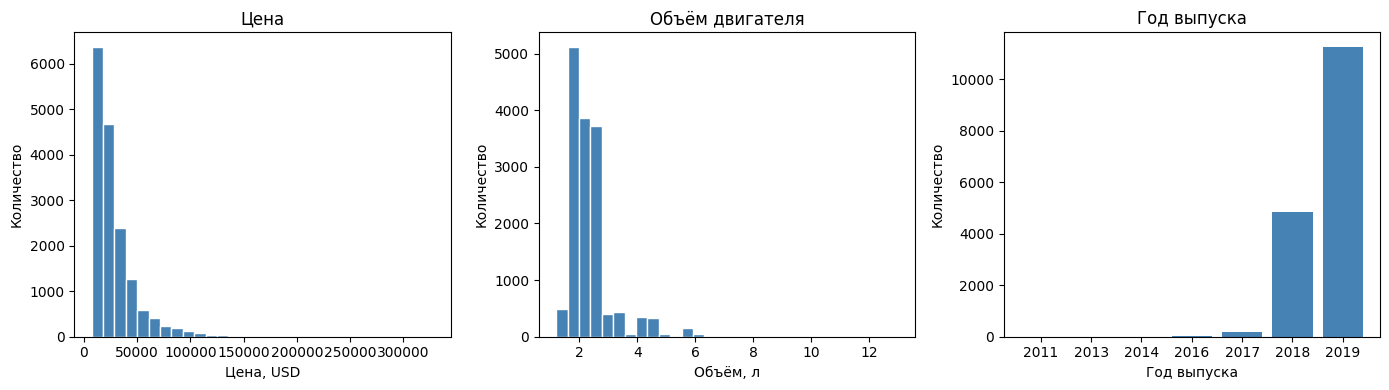

In [187]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(data['price_usd'].dropna(), bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Цена')
axes[0].set_xlabel('Цена, USD')
axes[0].set_ylabel('Количество')

axes[1].hist(data['engine_volume'].dropna().astype(float), bins=30, color='steelblue', edgecolor='white')
axes[1].set_title('Объём двигателя')
axes[1].set_xlabel('Объём, л')
axes[1].set_ylabel('Количество')

year_counts = data['year_of_release'].dropna().astype(int).value_counts().sort_index()
axes[2].bar(year_counts.index.astype(str), year_counts.values, color='steelblue')
axes[2].set_title('Год выпуска')
axes[2].set_xlabel('Год выпуска')
axes[2].set_ylabel('Количество')

fig.tight_layout()
plt.show()

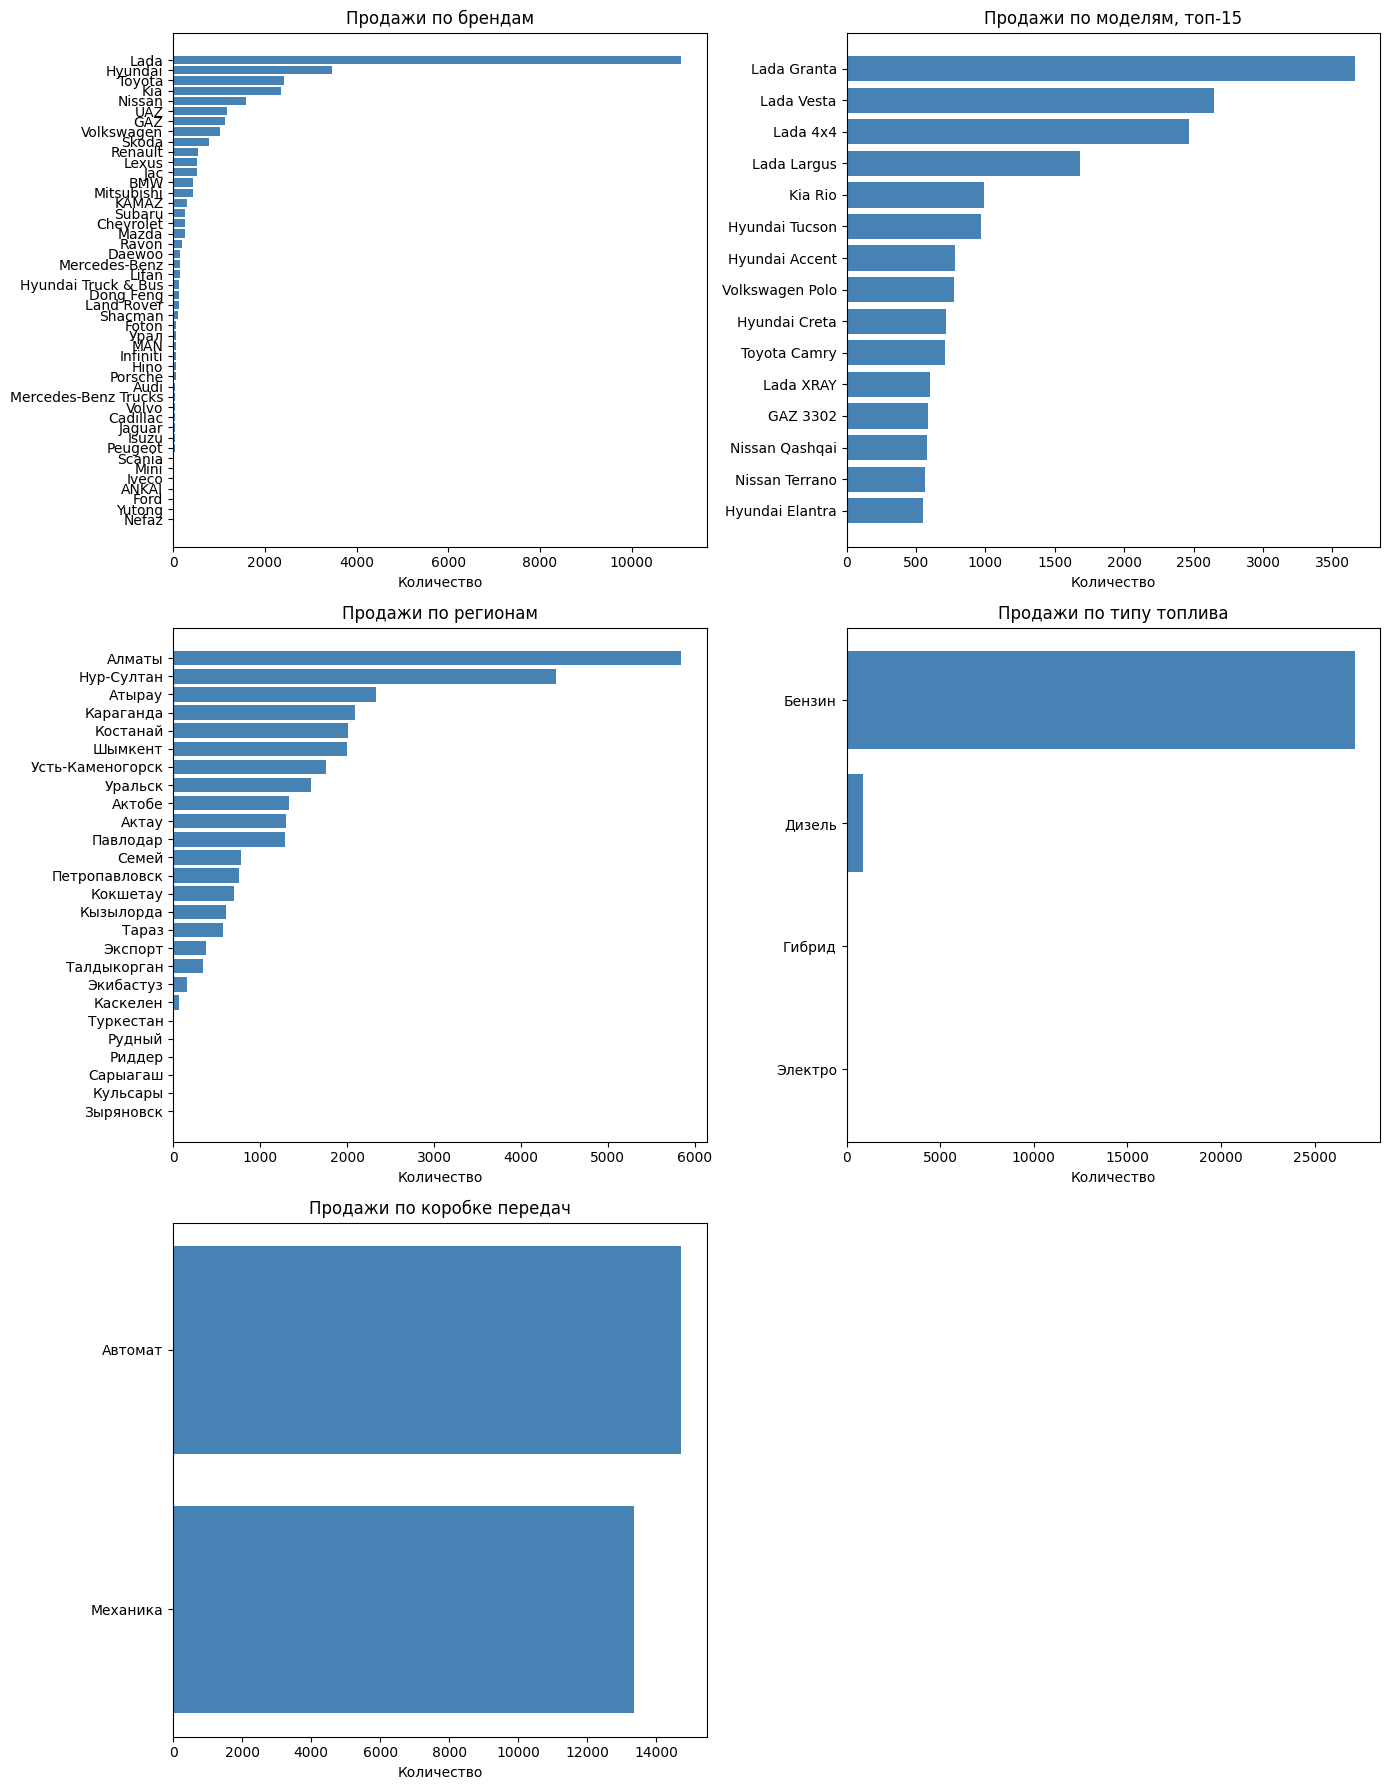

In [188]:
fuel_labels = {'F': 'Бензин', 'D': 'Дизель', 'E': 'Электро', 'HYB': 'Гибрид'}

def sales_by(column, top=None):
    sales = (
        data.groupby(column, observed=True)['quantity']
        .sum()
        .sort_values(ascending=True)
    )
    if top is not None:
        sales = sales.tail(top)
    return sales

brand_sales = sales_by('brand')
model_sales = (
    data.groupby(['brand', 'model'], observed=True)['quantity']
    .sum()
    .sort_values(ascending=True)
    .tail(15)
)
model_sales.index = model_sales.index.map(lambda item: f'{item[0]} {item[1]}')
region_sales = sales_by('region')
fuel_sales = sales_by('fuel_type')
fuel_sales.index = fuel_sales.index.map(lambda value: fuel_labels.get(value, value))
transmission_sales = sales_by('transmission')

fig, axes = plt.subplots(3, 2, figsize=(14, 18))
panels = [
    (axes[0, 0], brand_sales, 'Продажи по брендам'),
    (axes[0, 1], model_sales, 'Продажи по моделям, топ-15'),
    (axes[1, 0], region_sales, 'Продажи по регионам'),
    (axes[1, 1], fuel_sales, 'Продажи по типу топлива'),
    (axes[2, 0], transmission_sales, 'Продажи по коробке передач'),
]

for ax, sales, title in panels:
    ax.barh(sales.index.astype(str), sales.values, color='steelblue')
    ax.set_title(title)
    ax.set_xlabel('Количество')

axes[2, 1].axis('off')
fig.tight_layout()
plt.show()

Основные выводы:
1. Большая часть автомобилей продаётся по цене до 20 000 USD.
2. Большая часть автомобилей имеет объём двигателя до 2.0 л.
3. 2019 год — самый частый год выпуска.
4. Основные продажи приходятся на Алматы и Нур-Султан.
5. Бензин — самый частый тип топлива.
6. Автомат — самая частая коробка передач.
7. Самые продаваемые бренды: Lada, Hyundai, Toyota.
8. Самые продаваемые модели: Lada Granta, Lada Vesta, Lada 4x4.
9. В количестве есть аномалии: −1 у Skoda Superb — это возврат; 100 у Skoda Octavia и 115 у Lada 4x4 — оптовые заказы.

# Анализ рынка

In [189]:
def mercur_share(column):
    mercur = data['company'].eq('Mercur Auto')
    total = data.groupby(column, observed=True)[['quantity', 'sale_usd']].sum()
    mercur_part = data.loc[mercur].groupby(column, observed=True)[['quantity', 'sale_usd']].sum()
    table = total.join(mercur_part, lsuffix='_total', rsuffix='_mercur')
    table[['quantity_mercur', 'sale_usd_mercur']] = table[['quantity_mercur', 'sale_usd_mercur']].fillna(0)
    table['доля по количеству, %'] = (table['quantity_mercur'] / table['quantity_total'] * 100).round(1)
    table['доля по сумме, %'] = (table['sale_usd_mercur'] / table['sale_usd_total'] * 100).round(1)
    table = table.sort_values('доля по количеству, %', ascending=False)
    return table.rename(columns={
        'quantity_mercur': 'количество Меркур Авто',
        'quantity_total': 'все количество',
        'sale_usd_mercur': 'сумма Меркур Авто, USD',
        'sale_usd_total': 'вся сумма, USD',
    })[['количество Меркур Авто', 'все количество', 'доля по количеству, %',
        'сумма Меркур Авто, USD', 'вся сумма, USD', 'доля по сумме, %']]

brand_share = mercur_share('brand')
region_share = mercur_share('region')
segment_share = mercur_share('segmentation_2013')
class_share = mercur_share('class_2013')

share_format = {
    'количество Меркур Авто': '{:,.0f}',
    'все количество': '{:,.0f}',
    'доля по количеству, %': '{:.1f}',
    'сумма Меркур Авто, USD': '{:,.0f}',
    'вся сумма, USD': '{:,.0f}',
    'доля по сумме, %': '{:.1f}',
}

display(brand_share.style.format(share_format))
display(region_share.style.format(share_format))
display(segment_share.style.format(share_format))
display(class_share.style.format(share_format))

mercur = data['company'].eq('Mercur Auto')
mercur_check = data.loc[mercur, 'sale_usd'].sum() / data.loc[mercur, 'quantity'].sum()
others_check = data.loc[~mercur, 'sale_usd'].sum() / data.loc[~mercur, 'quantity'].sum()

average_check_table = pd.DataFrame({
    'средний чек, USD': [mercur_check, others_check, mercur_check - others_check],
}, index=['Меркур Авто', 'Остальной рынок', 'Разница'])

display(average_check_table.style.format('{:,.0f}'))

def sales_structure(column):
    mercur = data['company'].eq('Mercur Auto')
    mercur_mix = data.loc[mercur].groupby(column, observed=True)['quantity'].sum()
    market_mix = data.groupby(column, observed=True)['quantity'].sum()
    table = pd.DataFrame({
        'доля в продажах Меркур Авто, %': mercur_mix / mercur_mix.sum() * 100,
        'доля на рынке, %': market_mix / market_mix.sum() * 100,
    }).fillna(0)
    table['разница, п.п.'] = table['доля в продажах Меркур Авто, %'] - table['доля на рынке, %']
    return table.round(1).sort_values('доля в продажах Меркур Авто, %', ascending=False)

structure_segment = sales_structure('segmentation_2013')
structure_class = sales_structure('class_2013')
display(structure_segment.style.format('{:.1f}'))
display(structure_class.style.format('{:.1f}'))

,количество Меркур Авто,все количество,"доля по количеству, %","сумма Меркур Авто, USD","вся сумма, USD","доля по сумме, %"
brand,,,,,,
Porsche,52,52,100.0,"5,113,513","5,113,513",100.0
Audi,46,46,100.0,"3,585,759","3,585,759",100.0
Volkswagen,278,"1,024",27.1,"6,013,297","21,106,708",28.5
ANKAI,0,11,0.0,0,"1,255,324",0.0
Mazda,0,246,0.0,0,"7,237,722",0.0
Mercedes-Benz,0,145,0.0,0,"14,186,028",0.0
Mercedes-Benz Trucks,0,44,0.0,0,"3,432,444",0.0
Mini,0,16,0.0,0,"483,953",0.0
Mitsubishi,0,423,0.0,0,"14,245,533",0.0


,количество Меркур Авто,все количество,"доля по количеству, %","сумма Меркур Авто, USD","вся сумма, USD","доля по сумме, %"
region,,,,,,
Алматы,236,"5,844",4.0,"11,237,531","177,874,568",6.3
Атырау,41,"2,334",1.8,"759,991","43,798,161",1.7
Нур-Султан,51,"4,399",1.2,"1,502,141","116,590,260",1.3
Караганда,21,"2,095",1.0,"399,333","39,759,740",1.0
Уральск,14,"1,587",0.9,"290,652","30,338,021",1.0
Костанай,13,"2,005",0.6,"522,921","40,972,979",1.3
Актау,0,"1,300",0.0,0,"24,882,185",0.0
Сарыагаш,0,3,0.0,0,"29,654",0.0
Экибастуз,0,158,0.0,0,"1,828,688",0.0


,количество Меркур Авто,все количество,"доля по количеству, %","сумма Меркур Авто, USD","вся сумма, USD","доля по сумме, %"
segmentation_2013,,,,,,
Легковые автомобили,218,"13,219",1.6,"5,471,327","199,997,111",2.7
Внедорожники,143,"11,927",1.2,"8,632,599","349,113,208",2.5
Пикапы,2,297,0.7,"73,042","8,769,947",0.8
Коммерческие автомобили,8,"3,102",0.3,"251,411","97,688,004",0.3
Минивэны,5,"1,790",0.3,"284,190","22,010,356",1.3


,количество Меркур Авто,все количество,"доля по количеству, %","сумма Меркур Авто, USD","вся сумма, USD","доля по сумме, %"
class_2013,,,,,,
F класс,12,44,27.3,"1,545,729","4,596,442",33.6
Спортивные автомобили,2,10,20.0,"269,826","932,827",28.9
Полноразмерный Минивэн,5,42,11.9,"284,190","1,855,462",15.3
E класс,9,183,4.9,"699,853","8,676,859",8.1
Полноразмерные SUV,67,"1,771",3.8,"5,842,652","106,619,014",5.5
Микроавтобусы,8,375,2.1,"251,411","7,430,489",3.4
B класс,188,"10,037",1.9,"2,778,195","111,676,831",2.5
Компактные SUV,65,"3,735",1.7,"2,114,158","103,035,690",2.1
Pick-ups,2,297,0.7,"73,042","8,769,947",0.8


,"средний чек, USD"
Меркур Авто,"39,129"
Остальной рынок,"22,126"
Разница,"17,003"


,"доля в продажах Меркур Авто, %","доля на рынке, %","разница, п.п."
segmentation_2013,,,
Легковые автомобили,58.0,43.6,14.4
Внедорожники,38.0,39.3,-1.3
Коммерческие автомобили,2.1,10.2,-8.1
Минивэны,1.3,5.9,-4.6
Пикапы,0.5,1.0,-0.4


,"доля в продажах Меркур Авто, %","доля на рынке, %","разница, п.п."
class_2013,,,
B класс,50.0,33.1,16.9
Полноразмерные SUV,17.8,5.8,12.0
Компактные SUV,17.3,12.3,5.0
F класс,3.2,0.1,3.0
Среднеразмерные SUV,2.9,7.5,-4.6
E класс,2.4,0.6,1.8
Микроавтобусы,2.1,1.2,0.9
C класс,1.3,5.3,-4.0
Полноразмерный Минивэн,1.3,0.1,1.2


Сильные стороны «Меркур Авто»:
- Средний чек 39 129 USD, на 17 003 USD выше, чем у остального рынка.
- Компания продаёт весь объём Audi и Porsche и около трети Volkswagen. Это премиальный набор, поэтому чек выше рынка.
- В собственных продажах легковые автомобили занимают 58% против 44% на рынке.

Слабые стороны:
- Доля рынка около 1,2% и по количеству, и по сумме.
- Ассортимент узкий: только Audi, Porsche и Volkswagen. Массовых брендов нет, коммерческие автомобили почти не представлены (2% продаж компании против 10% рынка).
- Продажи сосредоточены в Алматы (около 63%). В остальных регионах доля компании ниже 2%.
